# Lab: Convolution from Scratch in NumPy

**CNN Fundamentals · NTI**

In this lab you will write the core operation of a CNN yourself, with nothing but NumPy.

**Goals**
1. Treat an image as an array of numbers.
2. Write `corr2d`: a 2D convolution with **stride** and **padding**.
3. Verify the **output size formula** from the slides.
4. Apply **edge-detection kernels** to a real photo.
5. Extend the idea to **multi-channel** images and **many filters**.

**How to work**
- Run the cells from top to bottom (`Shift + Enter`).
- Cells marked **TODO** need your code. Replace every `...` with your own code.
- The `check(...)` lines tell you with Good Job or Bad Luck whether your code is right.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate2d   # used only to verify OUR code

def check(name, condition):
    print(("Good Job " if condition else "Bad Luck ") + name)

# Photos that ship with scikit-image (no download needed), scaled to [0, 1]
try:
    from skimage import data
    photo = data.camera().astype(np.float32) / 255.0          # grayscale, 512 x 512
    rgb_photo = data.astronaut().astype(np.float32) / 255.0   # color, 512 x 512 x 3
except Exception:
    # Fallback: a synthetic image with clear edges
    yy, xx = np.mgrid[0:256, 0:256]
    photo = ((xx > 96) & (xx < 192) & (yy > 64) & (yy < 192)).astype(np.float32)
    rgb_photo = np.stack([photo, photo * 0.5, 1 - photo], axis=-1)

print("Ready.")

Ready.


## 1. An image is an array of numbers

Remember the slides: a grayscale image is a 2D **tensor** with shape `(H, W)`.

shape: (512, 512)
dtype: float32
min / max: 0.0 1.0


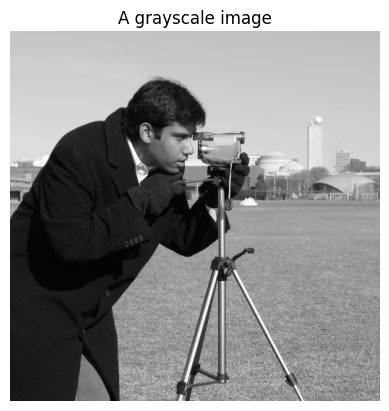

In [2]:
print("shape:", photo.shape)
print("dtype:", photo.dtype)
print("min / max:", photo.min(), photo.max())

plt.imshow(photo, cmap="gray")
plt.title("A grayscale image")
plt.axis("off")
plt.show()

In [3]:
# The numbers behind a tiny 6 x 6 patch of the image
print(np.round(photo[100:106, 100:106], 2))

[[0.83 0.83 0.83 0.84 0.83 0.83]
 [0.84 0.83 0.83 0.83 0.84 0.83]
 [0.84 0.84 0.84 0.83 0.83 0.83]
 [0.84 0.84 0.83 0.83 0.83 0.84]
 [0.84 0.83 0.84 0.83 0.84 0.84]
 [0.84 0.84 0.84 0.83 0.83 0.84]]


**Think:** How many numbers describe this image? What would the shape be for an RGB image of the same size?

## 2. Convolution by hand

We use the same example as the slides: a 5 × 5 input and a 3 × 3 kernel.

In [ ]:
X = np.array([[1, 0, 1, 0, 0],
              [1, 1, 1, 0, 0],
              [0, 0, 0, 1, 0],
              [1, 1, 0, 0, 1],
              [0, 0, 0, 1, 1]], dtype=float)

K = np.array([[1, 0, 1],
              [1, 1, 0],
              [0, 0, 1]], dtype=float)

# TODO: take the 3 x 3 patch in the top-left corner of X,
# multiply it element by element with K, and add all the products.
patch = ...
value = ...

print("top-left value:", value)
check("the top-left value is 4 (as on the slide)", value == 4)

## 3. Write `corr2d`

Now repeat that at every position. Your function must support:
- `padding`: add that many rings of zeros around the image (`np.pad`).
- `stride`: how many pixels the kernel moves each step.

The output size comes from the formula `O = floor((N + 2P - K) / S) + 1`.

In [ ]:
def corr2d(X, K, stride=1, padding=0):
    """Cross-correlate the 2D image X with the 2D kernel K."""
    # 1) TODO: pad X with zeros on all four sides
    Xp = ...

    kh, kw = K.shape
    H, W = Xp.shape

    # 2) TODO: output height and width (use the formula above)
    out_h = ...
    out_w = ...

    Y = np.zeros((out_h, out_w))

    # 3) TODO: slide the kernel over the padded image
    for i in range(out_h):
        for j in range(out_w):
            ...   # take the patch at (i, j), multiply with K, sum, store in Y[i, j]

    return Y

In [ ]:
Y = corr2d(X, K)
print(Y)

expected = np.array([[4, 3, 2],
                     [2, 1, 3],
                     [2, 3, 1]])
check("5x5 example matches the slide", Y.shape == (3, 3) and np.allclose(Y, expected))

rng = np.random.default_rng(0)
A = rng.random((9, 9))
B = rng.random((3, 3))
check("same result as scipy (no padding)", np.allclose(corr2d(A, B), correlate2d(A, B, mode="valid")))
check("padding=1 keeps the size", corr2d(A, B, padding=1).shape == A.shape)
check("stride=2 gives a 4 x 4 output", corr2d(A, B, stride=2).shape == (4, 4))

> **Note:** deep learning libraries compute exactly this operation (**cross-correlation**, the kernel is not flipped) and still call it *convolution*. For learned kernels the difference does not matter.

## 4. Check the output size formula

Write the formula as a function, then compare it with the shape that `corr2d` really produces. The rows are the same ones as in the slide.

In [ ]:
def output_size(N, K, P, S):
    # TODO: the formula from the slides
    return ...

rows = [  # N,  K,  P,  S, expected O
    (5, 3, 0, 1, 3),
    (5, 3, 1, 1, 5),
    (5, 3, 0, 2, 2),
    (28, 5, 0, 1, 24),
]

for N, k, P, S, expected_o in rows:
    real = corr2d(np.zeros((N, N)), np.ones((k, k)), stride=S, padding=P).shape[0]
    ok = output_size(N, k, P, S) == real == expected_o
    check(f"N={N}, K={k}, P={P}, S={S}  ->  O={real}", ok)

## 5. Edge detection

A hand-designed kernel that responds to **vertical edges** (dark on the left, bright on the right):

```
-1  0  1
-1  0  1
-1  0  1
```

First, the tiny image from the title slide: dark on the left, bright on the right.

In [ ]:
Kv = np.array([[-1, 0, 1],
               [-1, 0, 1],
               [-1, 0, 1]], dtype=float)

edge_demo = np.array([[12, 40, 200, 230],
                      [20, 60, 210, 240],
                      [15, 35, 190, 250],
                      [10, 45, 205, 245]], dtype=float)

print(corr2d(edge_demo, Kv))   # large values: there is a vertical edge

In [ ]:
# TODO: the horizontal-edge kernel. Hint: it is the transpose of Kv.
Kh = ...

edges_v = corr2d(photo, Kv)     # takes a few seconds
edges_h = corr2d(photo, Kh)
magnitude = np.sqrt(edges_v ** 2 + edges_h ** 2)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes,
                          [photo, np.abs(edges_v), np.abs(edges_h), magnitude],
                          ["Original", "Vertical edges", "Horizontal edges", "Both"]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

**Think:** Why does the vertical kernel light up the vertical edges but not the horizontal ones?

## 6. Padding and stride on a real image

In [ ]:
valid   = corr2d(photo, Kv)                          # P = 0, S = 1
same    = corr2d(photo, Kv, padding=1)               # P = 1, S = 1
strided = corr2d(photo, Kv, stride=2, padding=1)     # P = 1, S = 2

print("input  :", photo.shape)
print("valid  :", valid.shape)
print("same   :", same.shape)
print("stride2:", strided.shape)

check("same padding keeps the size", same.shape == photo.shape)
check("stride 2 roughly halves the size", strided.shape == (256, 256))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, [valid, same, strided],
                          [f"Valid {valid.shape}", f"Same {same.shape}", f"Stride 2 {strided.shape}"]):
    ax.imshow(np.abs(img), cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

**Think:** How many positions does the kernel visit with stride 1 and with stride 2? How is that related to the computation cost?

## 7. Color images and many filters

An RGB image has 3 channels, so the kernel needs depth 3. Each channel is multiplied with its own slice of the kernel and the results are **added** into one feature map.

In [ ]:
def corr2d_multi(X, K, stride=1, padding=0):
    """X has shape (C, H, W), K has shape (C, kh, kw). Returns one (H', W') feature map."""
    # TODO: apply corr2d to each channel with its own kernel slice, then add the results
    return ...

In [ ]:
img = rgb_photo[::2, ::2].transpose(2, 0, 1)    # (C, H, W) = (3, 256, 256), smaller to run faster
print("input:", img.shape)

# A bank of 4 filters, each of shape (3, 3, 3)  ->  shape (4, 3, 3, 3)
red_only = np.zeros((3, 3, 3)); red_only[0, 1, 1] = 1
bank = np.stack([
    np.stack([Kv] * 3),          # vertical edges on every channel
    np.stack([Kh] * 3),          # horizontal edges on every channel
    np.ones((3, 3, 3)) / 27,     # blur: average of a 3 x 3 x 3 block
    red_only,                    # keeps only the red channel
])
print("filter bank:", bank.shape)

feature_maps = np.stack([corr2d_multi(img, f) for f in bank])     # takes ~10 seconds
print("output:", feature_maps.shape)

check("4 filters give 4 output channels of 254 x 254", feature_maps.shape == (4, 254, 254))
print("parameters in this layer:", bank.size + 4, " = 4 x (3 x 3 x 3 + 1)")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(rgb_photo[::2, ::2]); axes[0].set_title("Input")
for ax, fm, title in zip(axes[1:], feature_maps,
                         ["Vertical edges", "Horizontal edges", "Blur", "Red only"]):
    ax.imshow(np.abs(fm) if "edges" in title else fm, cmap="gray")
    ax.set_title(title)
for ax in axes:
    ax.axis("off")
plt.show()

## 8. Check yourself

1. A 7 × 7 image, a 3 × 3 kernel, stride 2, no padding. What is the output size?
2. Which padding keeps a 5 × 5 kernel's output the same size as its input (stride 1)?
3. How many parameters does a convolution layer have with 16 filters, 3 input channels and 3 × 3 kernels?
4. Why do we usually not choose the kernel values by hand in a CNN?

*Verify your answers with `output_size(...)` and `corr2d_multi` from this notebook.*

---
**Next:** in the following lab you will let a framework learn the kernels for you, with a real **CNN** on Fashion-MNIST.